In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import math

In [2]:
rng = np.random.default_rng(42)

In [3]:
def oscillator(t, y):
    """
    Defines the system of first-order ODEs.
    y[0] = x  (position)
    y[1] = v  (velocity)
    """
    x, v = y
    dxdt = v
    dvdt = A0 * np.cos(w_drive * t) - 2 * gamma * v - w0**2 * x
    return [dxdt, dvdt]

# Oscillatore armonico libero

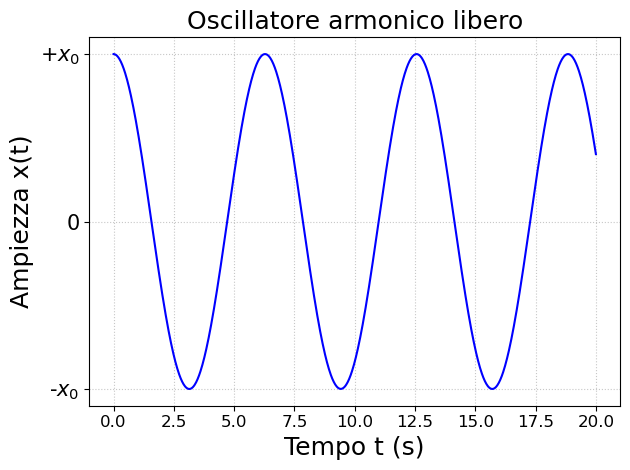

In [4]:
# Parameters
w0 = 1.0  # Natural frequency (rad/s)
gamma = 0   # Damping coefficient
A0 = 0     # Driving force amplitude

w_drive = w0  # Driving frequency set to natural frequency for resonance

# Initial conditions: x(0) = 1.0, v(0) = 0.0
x_0 = 1.0
v_0 = 0.0
y0 = [x_0, v_0]

t_span = (0, 20)
t_eval = np.linspace(t_span[0], t_span[1], 1000)

# Solve the ODE
sol = solve_ivp(oscillator, t_span, y0, t_eval=t_eval)


plt.plot(sol.t, sol.y[0], color='b', label=f'Driving $\omega$ = {w_drive} rad/s')
plt.title("Oscillatore armonico libero", fontsize=18)
plt.xlabel('Tempo t (s)', fontsize=18)
plt.ylabel('Ampiezza x(t)', fontsize=18)
plt.grid(True)
plt.yticks(ticks=[x_0, 0.0, -x_0], labels=[r"+$x_0$", "0", r"-$x_0$"], fontsize=15)
plt.xticks(fontsize=12)
plt.grid(True, linestyle=":", alpha=0.7)
plt.tight_layout()
plt.show()

# Oscillatore armonico smorzato

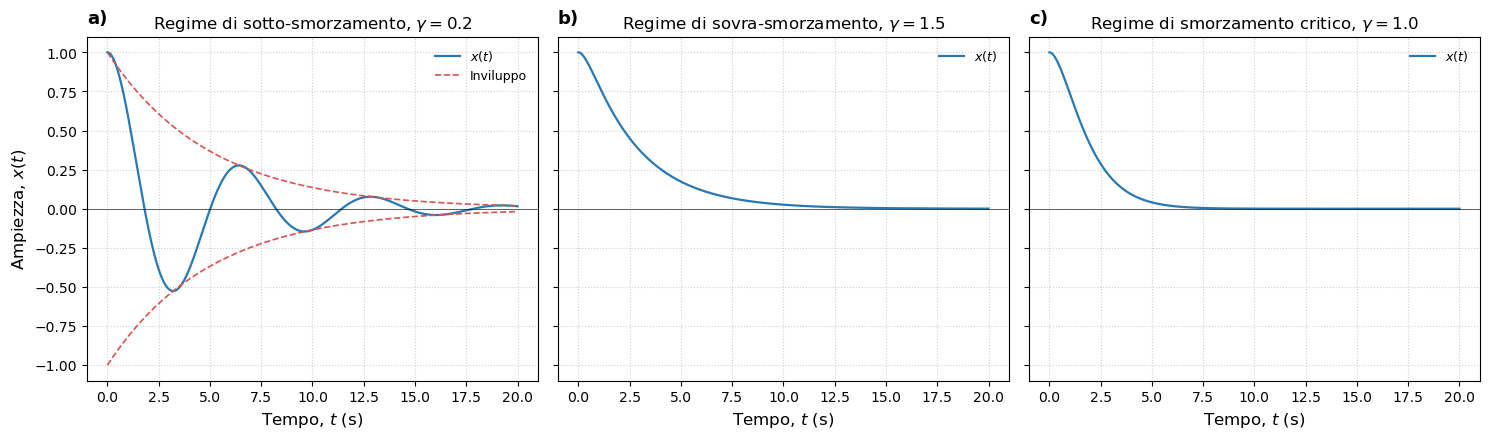

In [5]:
# Parameters
w0 = 1.0
A0 = 0.0
w_drive = w0

# Initial conditions
x_0 = 1.0
v_0 = 0.0
y0 = [x_0, v_0]

# Time interval
t_span = (0, 20)
t_eval = np.linspace(*t_span, 1000)

# Damping coefficients
gammas = [0.2, 1.5, 1.0]

titles = [
    "Regime di sotto-smorzamento",
    "Regime di sovra-smorzamento",
    "Regime di smorzamento critico"
]
labels = ["a)", "b)", "c)"]

# Create figure
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4.5),
    sharex=True,
    sharey=True
)

for ax, gamma_value, title, panel in zip(
    axes, gammas, titles, labels
):
    # Update the global damping coefficient
    gamma = gamma_value

    # Solve the ODE using the current global gamma
    sol = solve_ivp(
        oscillator,
        t_span,
        y0,
        t_eval=t_eval
    )

    # Plot trajectory
    ax.plot(
        sol.t, sol.y[0],
        color="#2878B5",
        linewidth=1.6,
        label=r"$x(t)$"
    )

    # Plot envelope in the underdamped regime
    if gamma < w0:
        envelope = x_0 * np.exp(-gamma * sol.t)

        ax.plot(
            sol.t, envelope,
            color="#D9534F",
            linestyle="--",
            linewidth=1.2,
            label="Inviluppo"
        )
        ax.plot(
            sol.t, -envelope,
            color="#D9534F",
            linestyle="--",
            linewidth=1.2
        )

    # Reference line
    ax.axhline(0, color="black", linewidth=0.7, alpha=0.6)

    # Titles and labels
    ax.set_title(
        rf"{title}, " + rf"$\gamma={gamma:.1f}$",
        fontsize=12
    )
    ax.set_xlabel(r"Tempo, $t$ (s)", fontsize=12)

    ax.text(
        0.0, 1.08, panel,
        transform=ax.transAxes,
        fontsize=13,
        fontweight="bold",
        va="top"
    )

    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(fontsize=9, frameon=False)

axes[0].set_ylabel(r"Ampiezza, $x(t)$", fontsize=12)

# fig.suptitle(
#     "Oscillatore smorzato nei tre regimi di smorzamento",
#     fontsize=15
# )

plt.tight_layout()
plt.show()

# Battimenti

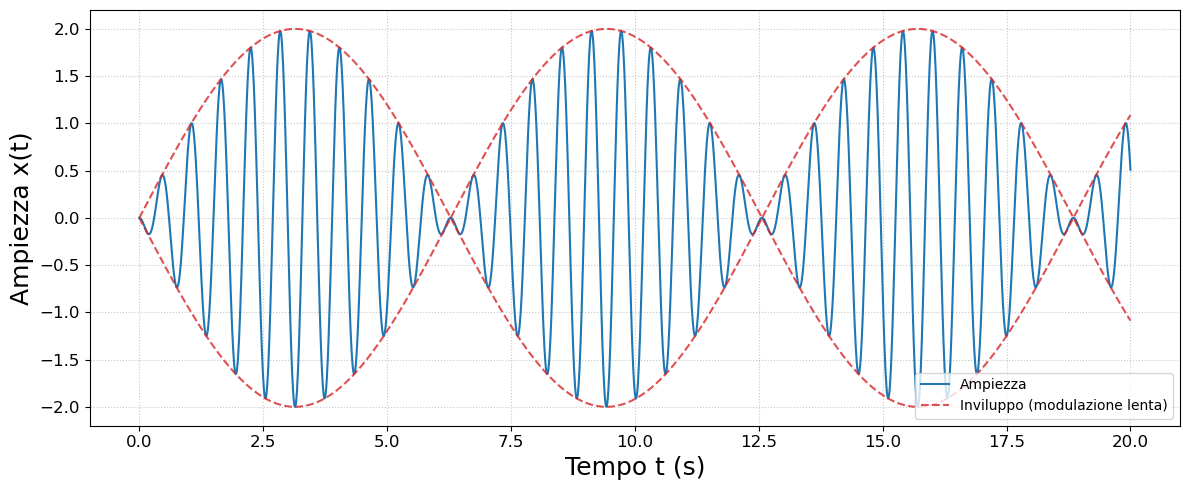

In [6]:
# Definiamo le frequenze (vicine tra loro per creare i battimenti)
w0 = 10.0  # Frequenza naturale (pulsazione rad/s)
w = 11.0   # Frequenza della forzante esterna (rad/s)

t = np.linspace(0, 20, 2000)

x = np.cos(w * t) - np.cos(w0 * t)

inviluppo = 2 * np.sin(abs(w0 - w) / 2 * t)

plt.figure(figsize=(12, 5))
plt.plot(t, x, color='tab:blue', label="Ampiezza".format(w0, w))
plt.plot(t, inviluppo, color='tab:red', linestyle='--', alpha=0.8, label='Inviluppo (modulazione lenta)')
plt.plot(t, -inviluppo, color='tab:red', linestyle='--', alpha=0.8)
# plt.title("Battimenti in un Oscillatore Armonico Forzato", fontsize=18)
plt.xlabel("Tempo t (s)", fontsize=18)
plt.ylabel("Ampiezza x(t)", fontsize=18)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(loc="lower right")
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

# Oscillatore forzato

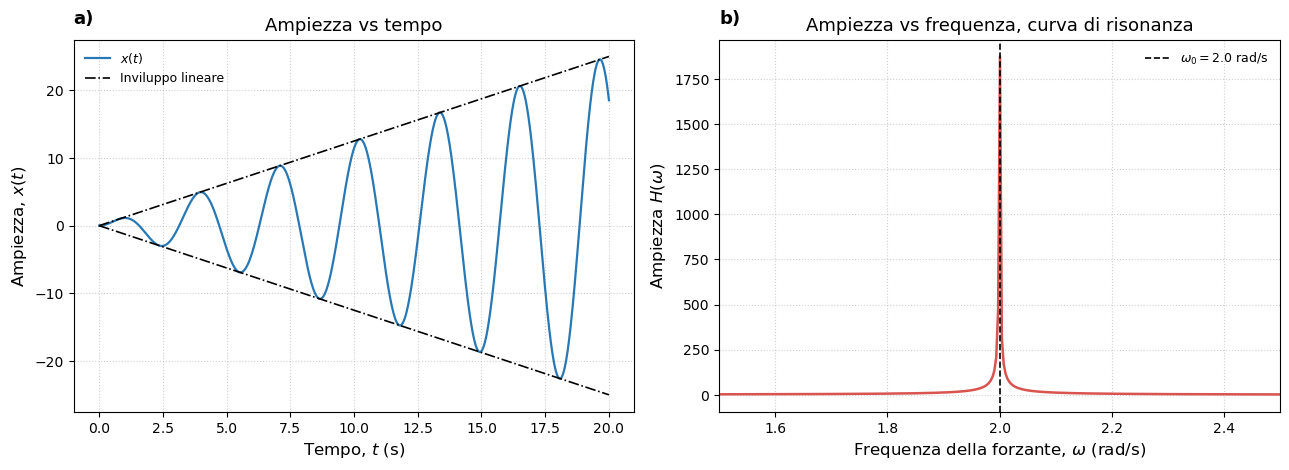

In [7]:
# Parameters
w0 = 2.0
gamma = 0.0
A0 = 5.0
w_drive = w0

# Initial conditions
x_0 = 0.0
v_0 = 0.0
y0 = [x_0, v_0]

# Time interval
t_span = (0, 20)
t_eval = np.linspace(*t_span, 1000)

# Solve the ODE
sol = solve_ivp(oscillator, t_span, y0, t_eval=t_eval)

# Frequency-domain solution
w_range = np.linspace(0, 10, 3000)

amplitude = A0 / np.sqrt((w0**2 - w_range**2)**2 + (2 * gamma * w_range)**2)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

ax = axes[0]
ax.plot(sol.t, sol.y[0], color="#2878B5", linewidth=1.6, label=r"$x(t)$")
envelope = A0 * sol.t / (2 * w0)
ax.plot(sol.t, envelope, color="black", linestyle="-.", linewidth=1.2, label="Inviluppo lineare")
ax.plot( sol.t, -envelope, color="black", linestyle="-.", linewidth=1.2)
ax.set_title("Ampiezza vs tempo", fontsize=13)
ax.set_xlabel(r"Tempo, $t$ (s)", fontsize=12)
ax.set_ylabel(r"Ampiezza, $x(t)$", fontsize=12)
ax.text(
    0.0, 1.08, "a)",
    transform=ax.transAxes,
    fontsize=13, fontweight="bold",
    va="top"
)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(frameon=False, fontsize=9)

ax = axes[1]
ax.plot(w_range, amplitude, color="#D9534F", linewidth=1.8)
ax.axvline(
    w0,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label=rf"$\omega_0={w0:.1f}$ rad/s"
)
ax.set_title("Ampiezza vs frequenza, curva di risonanza", fontsize=13)
ax.set_xlabel(r"Frequenza della forzante, $\omega$ (rad/s)", fontsize=12)
ax.set_ylabel(r"Ampiezza $H(\omega)$", fontsize=12)
ax.set_xlim(1.5, 2.5)
ax.text(
    0.0, 1.08, "b)",
    transform=ax.transAxes,
    fontsize=13, fontweight="bold",
    va="top"
)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(frameon=False, fontsize=9)

# fig.suptitle(
#     "Risonanza in un oscillatore armonico forzato",
#     fontsize=15
# )
plt.tight_layout()
plt.show()

# Risonanza

Q = 10.00
Resonance frequency wr = 0.997 rad/s


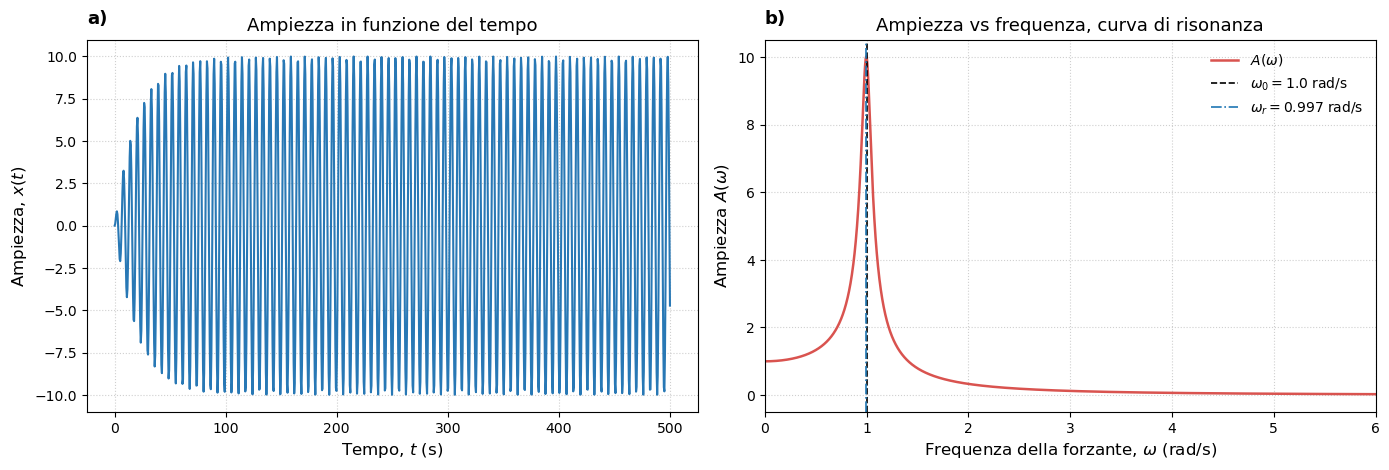

In [8]:
w0 = 1.0
gamma = 0.05
A0 = 1.0
w_drive = w0

# Initial conditions
x_0 = 0.0
v_0 = 0.0
y0 = [x_0, v_0]

# Time interval
t_span = (0, 500)
t_eval = np.linspace(*t_span, 1000)

# Solve the ODE
sol = solve_ivp(
    oscillator,
    t_span,
    y0,
    t_eval=t_eval
)

# Frequency-domain solution
w_range = np.linspace(0, 10, 5000)

amplitude = A0 / np.sqrt(
    (w0**2 - w_range**2)**2
    + (2 * gamma * w_range)**2
)

# Resonance frequency and quality factor
wr = np.sqrt(w0**2 - 2 * gamma**2)
Q = w0 / (2 * gamma)

print(f"Q = {Q:.2f}")
print(f"Resonance frequency wr = {wr:.3f} rad/s")

# Create two horizontal panels
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 4.8)
)

# --- (a) Time-domain solution ---
ax = axes[0]

ax.plot(
    sol.t, sol.y[0],
    color="#2878B5",
    linewidth=1.5
)

ax.set_title("Ampiezza in funzione del tempo", fontsize=13)
ax.set_xlabel(r"Tempo, $t$ (s)", fontsize=12)
ax.set_ylabel(r"Ampiezza, $x(t)$", fontsize=12)

ax.text(
    0.0, 1.08, "a)",
    transform=ax.transAxes,
    fontsize=13,
    fontweight="bold",
    va="top"
)

ax.grid(True, linestyle=":", alpha=0.6)

# --- (b) Frequency-domain solution ---
ax = axes[1]

ax.plot(
    w_range, amplitude,
    color="#D9534F",
    linewidth=1.8,
    label=r"$A(\omega)$"
)

ax.axvline(
    w0,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label=rf"$\omega_0={w0:.1f}$ rad/s"
)

ax.axvline(
    wr,
    color="tab:blue",
    linestyle="-.",
    linewidth=1.2,
    label=rf"$\omega_r={wr:.3f}$ rad/s"
)

ax.set_title("Ampiezza vs frequenza, curva di risonanza", fontsize=13)
ax.set_xlabel(r"Frequenza della forzante, $\omega$ (rad/s)", fontsize=12)
ax.set_ylabel(r"Ampiezza $A(\omega)$", fontsize=12)
ax.set_xlim(0, 6)

ax.text(
    0.0, 1.08, "b)",
    transform=ax.transAxes,
    fontsize=13,
    fontweight="bold",
    va="top"
)

ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(fontsize=10, frameon=False)

# fig.suptitle(
#     rf"Oscillatore armonico in risonanza ($Q={Q:.1f}$)",
#     fontsize=15
# )

plt.tight_layout()
plt.show()

# Langevin dynamics

In [9]:
def drift(x, a):
    return x * (a - x**2)

def simulate_langevin(a, eps, x0, T, dt, rng, n_paths=1, save_every=1):
    """Return (t, X) with X.shape = (n_saved, n_paths)."""
    n_steps = int(round(T / dt))
    x = np.full(n_paths, x0, dtype=float)
    n_saved = n_steps // save_every + 1
    X = np.empty((n_saved, n_paths))
    X[0] = x
    sq = eps * np.sqrt(dt)
    for k in range(1, n_steps + 1):
        x = x + drift(x, a) * dt + sq * rng.standard_normal(n_paths)
        if k % save_every == 0:
            X[k // save_every] = x
    t = np.arange(n_saved) * dt * save_every
    return t, X

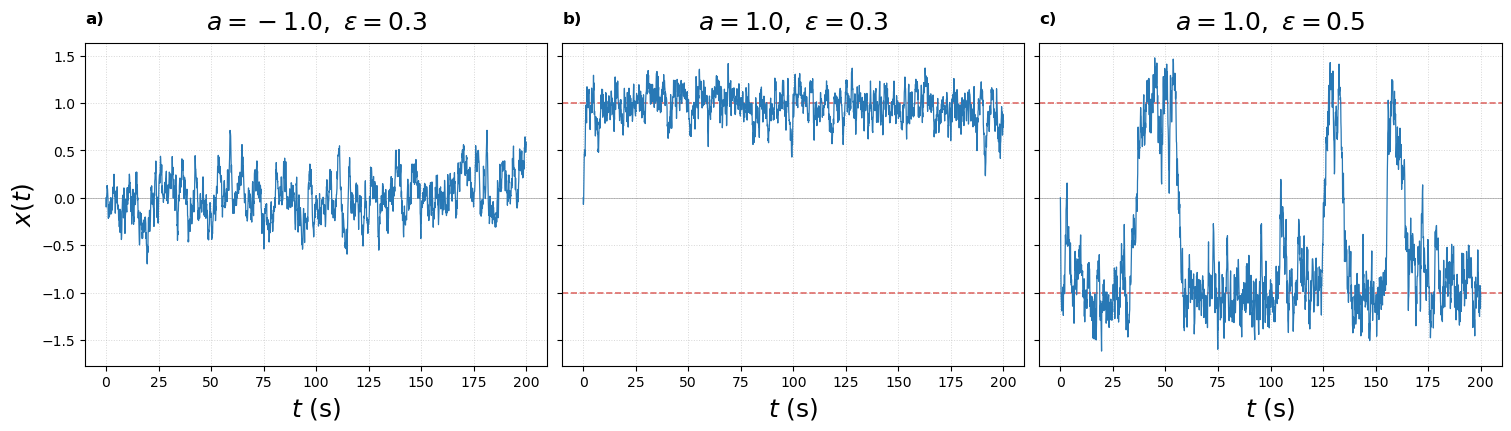

In [10]:
# Stile grafico
plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 13,
    "axes.labelsize": 14,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "lines.linewidth": 1.0,
    "axes.spines.top": True,
    "axes.spines.right": True,
})

params = [(-1.0, 0.3), (1.0, 0.3), (1.0, 0.5)]

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4.2),
    sharey=True,
    constrained_layout=True
)

for i, (ax, (a, eps)) in enumerate(zip(axes, params)):

    t, X = simulate_langevin(
        a, eps,
        x0=0.0,
        T=200,
        dt=0.01,
        n_paths=1,
        save_every=10,
        rng=rng
    )

    ax.plot(t, X, color="#2878B5", lw=0.9, zorder=3)

    # Equilibri stabili per a > 0
    if a > 0:
        eq = np.sqrt(a)
        ax.axhline(
            eq, color="#D9534F",
            ls="--", lw=1.2, alpha=0.85,
#             label=r"$x^*=\pm{}$".format(np.round(np.sqrt(a), 2)) if i == 1 else None
        )
        ax.axhline(
            -eq, color="#D9534F",
            ls="--", lw=1.2, alpha=0.85
        )

    ax.axhline(0, color="gray", lw=0.7, alpha=0.5)
    ax.grid(True, ls=":", lw=0.7, alpha=0.5)

    ax.set_title(
        rf"$a={a:.1f},\ \varepsilon={eps:.1f}$",
        pad=10,
        fontsize=18
    )
    ax.set_xlabel(r"$t$ (s)", fontsize=18)

    ax.text(
        0.0, 1.1, f"{chr(97+i)})",
        transform=ax.transAxes,
        ha="left", va="top",
        fontweight="bold"
    )

axes[0].set_ylabel(r"$x(t)$", fontsize=18)

# Legenda condivisa per gli equilibri
# axes[1].legend(loc="upper right", frameon=False, fontsize=10)

# fig.suptitle(
#     "Traiettorie stocastiche al variare dei parametri",
#     fontsize=18,
#     fontweight="semibold"
# )

plt.show()

# Tilted double potential

In [11]:
def tilted_double_well_potential(x, a, A, Omega, t):
    V = x**4/4 - a*x**2/2 - A * x * np.cos(Omega * t)
    return V

In [12]:
def create_t_label(t):
    if t == np.pi/2:
        t_label_title = "$\pi/2$"
    elif t == np.pi:
        t_label_title = "$\pi$"
    elif t == 3*np.pi/2:
        t_label_title = "3$\pi$/2"
    elif t == 2*np.pi:
        t_label_title = "2$\pi$"
    else:
        t_label_title = str(round(t,2))
    return t_label_title

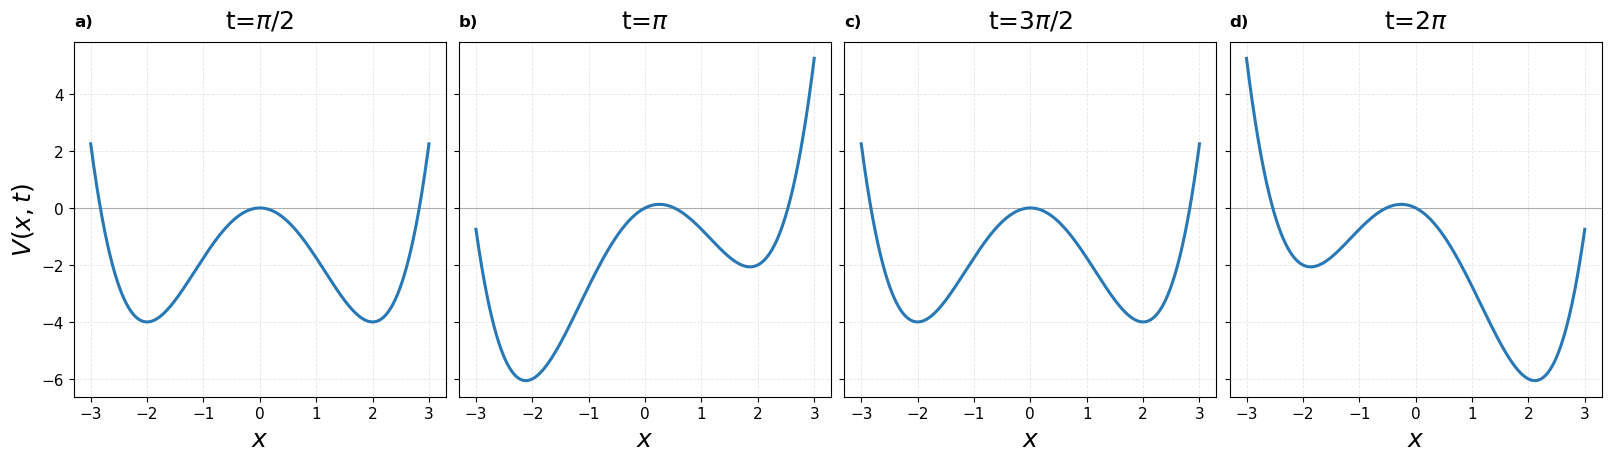

In [13]:
a = 4
A = 1
Omega = 1

x = np.linspace(-3, 3, 10000)

# Stile generale
plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 18,
    "axes.labelsize": 15,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "figure.titlesize": 17,
    "lines.linewidth": 2.2,
    "axes.spines.top": True,
    "axes.spines.right": True,
})

times = [np.pi/2, np.pi, 3*np.pi/2, 2*np.pi]

fig, axes = plt.subplots(
    1, 4,
    figsize=(16, 4.5),
    sharey=True,
    constrained_layout=True
)

# Colori uniformi per tutti i pannelli
color = "#2878B5"

for i, (ax, t) in enumerate(zip(axes, times)):
    t_label_title = create_t_label(t)
    V = tilted_double_well_potential(x, a, A, Omega, t)

    ax.plot(x, V, color=color, zorder=3)
    ax.axhline(0, color="gray", linewidth=0.8, alpha=0.6)
    ax.grid(True, linestyle="--", linewidth=0.6, alpha=0.3)

    ax.set_title("t="+t_label_title, pad=10)
    ax.set_xlabel(r"$x$", fontsize=18)

    # Etichetta del tempo nel pannello
    ax.text(
        0, 1.08, f"{chr(97+i)})",
        transform=ax.transAxes,
        va="top", ha="left",
        fontsize=12, fontweight="bold"
    )

axes[0].set_ylabel(r"$V(x,t)$", fontsize=18)

# fig.suptitle(
#     "Potenziale a doppia buca in presenza di forzante",
#     fontweight="semibold", fontsize=18
# )

plt.show()

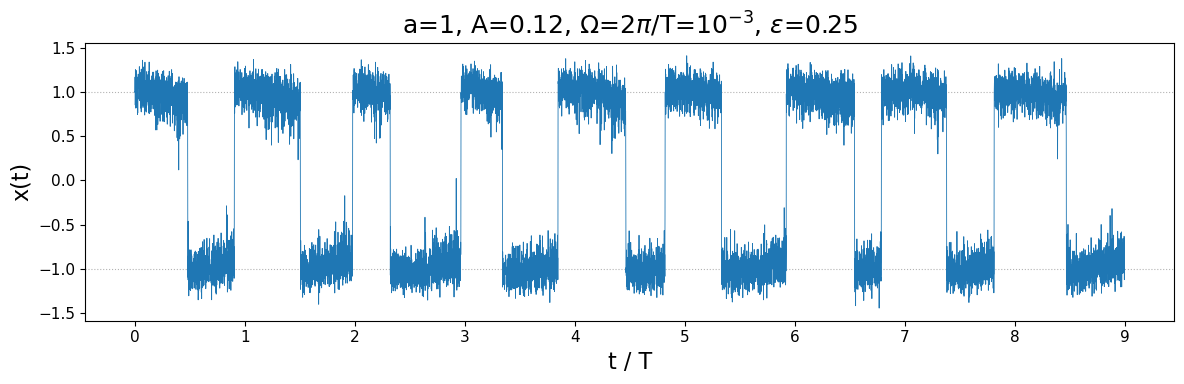

In [16]:
# ----------------------------------------------------------------------------
# Euler-Maruyama integrator for the forced equation (vectorised over paths)
# ----------------------------------------------------------------------------
def simulate(a, A, Omega, eps, T, dt=0.05, n_paths=1, stride=10, rng=1):
    """Return (t, X); X.shape = (n_saved, n_paths). Paths start in the right well."""
    n = int(round(T / dt))
    x = np.full(n_paths, math.sqrt(a))
    ns = n // stride + 1
    X = np.empty((ns, n_paths))
    X[0] = x
    sq = eps * math.sqrt(dt)
    for k in range(1, n + 1):
        f = A * math.cos(Omega * (k - 1) * dt)
        x = x + (x * (a - x * x) + f) * dt + sq * rng.standard_normal(n_paths)
        if k % stride == 0:
            X[k // stride] = x
    return np.arange(ns) * dt * stride, X

Om = 1e-3
T = 9 * 2 * math.pi / Om
t, X = simulate(1.0, 0.12, Om, 0.25, T, dt=0.1, stride=50, rng=rng)
T_ = 2 * math.pi / Om

x_ticks = range(0, 10, 1)

plt.figure(figsize=(12, 4))
plt.axhline(y=1, linestyle=":", linewidth=0.8, color="gray", alpha=0.6)
plt.axhline(y=-1, linestyle=":", linewidth=0.8, color="gray", alpha=0.6)
plt.plot(t / T_, X[:, 0], lw=0.6)
plt.xlabel("t / T", fontsize=16)
plt.xticks(ticks=x_ticks, labels=[str(i) for i in x_ticks])
plt.ylabel("x(t)", fontsize=16)
plt.title(r"a=1, A=0.12, $\Omega$=2$\pi$/T=$10^{-3}$, $\varepsilon$=0.25")
plt.tight_layout()